# Module: Comparison against real observational data

> Item (2) of the 3-part plan: check that the spectra/colors/luminosities
> `watercolor` paints -- now using the calibrated dust model from
> `04c_dust_model_population.ipynb` and the real per-galaxy OpenCosmo
> catalog -- land in the right place relative to real survey data, the way
> `Mocks_v3_data/reports/patch0` does for the supermock.

## What this compares against

Reduced, bundled copies of the same real datasets
`Mocks_v3/validation/collect_report_data.py` uses (same cuts, so this is an
apples-to-apples comparison target), under
`watercolor/data/observations/` (~10 MB total; the raw sources are a
107 MB SDSS array and a 2.25 GB AllWISE table, subsampled here the same way
that report subsamples them):

* **SDSS** (`sdss_colors.npz`, 60,000 objects) and **DEEP2**
  (`DEEP2.npy`, kept whole) -- `u-g, g-i, r-i, i-z, mag_i` colors +
  errors + spec-z. Column order is a documented gotcha: it is **not**
  "u-g, g-i, i-r, r-z" -- getting this backwards previously drove a
  calibration to zero (see `04c`'s and `Mocks_v3`'s notes on the same
  files).
* **AllWISE all-sky locus** (`wise_locus.npz`, 40,000 objects, no redshift)
  and **WISExSCOS photo-z crossmatch** (`wise_xscos_photoz.fits`, 4,346
  objects, has `z_phot`) -- Vega `W1-W2, W2-W3, W3-W4, W1` colors.
* **GAMA median SED stacks** (`gama_sed_stacks.csv`) -- pre-stacked
  observed-frame `f_nu` [mJy] vs rest wavelength in `(z, logM*)` bins
  (`z in {0.05,0.1,0.15,0.2}`, `logM* in {10.0,10.5,11.0}`), already reduced
  observational data (not object-level).

## Why per-particle painting needs a different sampling strategy here

`Mocks_v3`'s supermock is a full lightcone -- every galaxy already has a
realistic assigned redshift. `watercolor`'s HACC catalog
(`SPHEREx/.../output/step_624`, the same real per-galaxy OpenCosmo catalog
`04c` validated against) is a single **z=0 snapshot**. To compare against
surveys spanning `z ~ 0.01-1.4`, this notebook assigns each sampled galaxy
a redshift drawn from the surveys' combined range and redshifts/dims its
(z=0-built) rest-frame SED to that assigned z -- a reasonable approximation
for checking broadband colors and continuum shape, but **not** a real
lightcone: no mass/SFH evolution with cosmic time is modeled. That
caveat -- and (3) performance -- remain explicitly out of scope, same as
`04c`.

In [ ]:
#| default_exp obs_comparison

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| export
import os
import numpy as np
from importlib.resources import files as _pkg_files

OBS_DATA_DIR = "data/observations/"

SDSS_COLORS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "sdss_colors.npz"))
DEEP2_COLORS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "DEEP2.npy"))
WISE_LOCUS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "wise_locus.npz"))
WISE_XSCOS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "wise_xscos_photoz.fits"))
GAMA_SED_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "gama_sed_stacks.csv"))

## Loading the bundled observational data

Column convention (verified against `Mocks_v3/validation/calibrate_dust.py`
and reproduced by construction here, since these files were reduced with
the same cuts): SDSS/DEEP2 `colors` are `[u-g, g-i, r-i, i-z, mag_i]`.

In [ ]:
#| export

SURVEY_COLOR_COLUMNS = ('u-g', 'g-i', 'r-i', 'i-z', 'mag_i')


def _clean_survey_colors(colors:np.ndarray=None, # (N,5) [u-g,g-i,r-i,i-z,mag_i]
                         err_colors:np.ndarray=None, # (N,5) matching errors
                         z:np.ndarray=None, # (N,) spec-z
                         zrange:tuple=(0.0, 10.0), # Redshift selection window
                         mag_range:tuple=(10.0, 28.0), # mag_i selection window
                         color_clip:float=6.0, # |color| < color_clip for the 4 colors
                         )-> tuple: # (colors, err_colors, z), rows passing all cuts
    '''Same cuts Mocks_v3/validation/calibrate_dust.load_survey applies.'''
    colors = np.asarray(colors, dtype=float)
    err_colors = np.asarray(err_colors, dtype=float)
    z = np.asarray(z, dtype=float)
    mag_i = colors[:, 4]
    mask = (np.all(np.isfinite(colors), axis=1) & np.all(np.isfinite(err_colors), axis=1)
            & np.isfinite(z)
            & np.all(err_colors >= 0, axis=1) & np.all(err_colors[:, :4] < 5, axis=1)
            & (z >= zrange[0]) & (z <= zrange[1])
            & (mag_i > mag_range[0]) & (mag_i < mag_range[1])
            & np.all(np.abs(colors[:, :4]) < color_clip, axis=1))
    return colors[mask], err_colors[mask], z[mask]


def load_sdss_colors(path:str=None, # None -> bundled SDSS_COLORS_FILE
                     )-> dict: # colors, err_colors, z, columns -- pre-cut to Mocks_v3's SDSS window (z in [0.01,0.40])
    d = np.load(path or SDSS_COLORS_FILE)
    return dict(colors=d['colors'], err_colors=d['err_colors'], z=d['z'],
               columns=SURVEY_COLOR_COLUMNS)


def load_deep2_colors(path:str=None, # None -> bundled DEEP2_COLORS_FILE
                      )-> dict: # colors, err_colors, z, columns -- cut to Mocks_v3's DEEP2 window (z in [0.05,1.40])
    d = np.load(path or DEEP2_COLORS_FILE, allow_pickle=True)
    colors, err_colors, z = _clean_survey_colors(d['colors'], d['err_colors'], d['zspec'],
                                                 zrange=(0.05, 1.40))
    return dict(colors=colors, err_colors=err_colors, z=z, columns=SURVEY_COLOR_COLUMNS)

In [ ]:
#| export

WISE_VEGA_TO_AB = (2.699, 3.339, 5.174, 6.620)  # W1,W2,W3,W4: AB = Vega + offset
WISE_COLOR_COLUMNS = ('W1-W2', 'W2-W3', 'W3-W4', 'W1')


def load_wise_locus(path:str=None, # None -> bundled WISE_LOCUS_FILE
                    )-> dict: # AB colors/errs from the AllWISE all-sky locus (no redshift)
    '''AllWISE all-sky sample (SNR-cut, W2-W3>1.5 stellar-locus veto -- see
    Mocks_v3/validation/collect_report_data.py). Colors are Vega-mag
    differences (offsets cancel), W1 itself converted to AB.'''
    d = np.load(path or WISE_LOCUS_FILE)
    colors = np.array(d['colors'], dtype=float)
    colors[:, 3] += WISE_VEGA_TO_AB[0]  # W1 Vega -> AB; the 3 colors are offset-invariant
    return dict(colors=colors, err_colors=np.array(d['err_colors'], dtype=float),
               columns=WISE_COLOR_COLUMNS)


def load_wise_xscos(path:str=None, # None -> bundled WISE_XSCOS_FILE
                    )-> dict: # AB colors/errs/z from the WISExSCOS photo-z crossmatch
    from astropy.io import fits
    with fits.open(path or WISE_XSCOS_FILE) as hdul:
        t = hdul[1].data
        mask = np.isfinite(t['z_phot']) & (t['z_phot'] > 0) & (t['z_phot'] < 1)
        for b in (1, 2, 3, 4):
            mask &= np.isfinite(t[f'w{b}mpro']) & np.isfinite(t[f'w{b}sigmpro'])
        w = {b: np.asarray(t[f'w{b}mpro'], dtype=float)[mask] for b in (1, 2, 3, 4)}
        we = {b: np.asarray(t[f'w{b}sigmpro'], dtype=float)[mask] for b in (1, 2, 3, 4)}
        z = np.asarray(t['z_phot'], dtype=float)[mask]
    colors = np.column_stack([w[1] - w[2], w[2] - w[3], w[3] - w[4], w[1] + WISE_VEGA_TO_AB[0]])
    err_colors = np.column_stack([np.hypot(we[1], we[2]), np.hypot(we[2], we[3]),
                                  np.hypot(we[3], we[4]), we[1]])
    return dict(colors=colors, err_colors=err_colors, z=z, columns=WISE_COLOR_COLUMNS)

In [ ]:
#| export

import csv as _csv


def load_gama_sed_stacks(path:str=None, # None -> bundled GAMA_SED_FILE
                         )-> dict: # wave_um, and {(z, logM): f_nu_mJy} for each bin column
    '''GAMA median-stacked observed-frame SEDs in (z, logM*) bins
    (Richard_GAMA_SED_103122_median_stack_z_Mstar_bins.csv) -- already
    reduced observational data, used as-is.'''
    path = path or GAMA_SED_FILE
    with open(path, newline='') as f:
        reader = _csv.reader(f)
        header = next(reader)
        rows = [[float(x) for x in row] for row in reader]
    rows = np.array(rows)
    wave_um = rows[:, 0]
    stacks = {}
    for col_idx, name in enumerate(header[1:], start=1):
        # name like 'f_nu_mJy_z0.1_m10.5' -> ['f','nu','mJy','z0.1','m10.5']
        parts = name.split('_')
        z_val = float(parts[3][1:])
        m_val = float(parts[4][1:])
        stacks[(z_val, m_val)] = rows[:, col_idx]
    return dict(wave_um=wave_um, stacks=stacks)

In [ ]:
#| hide

# Imports used only by this notebook's demo/comparison cells below (not
# part of the exported watercolor.obs_comparison module). Kept in one
# pure-import cell -- see 04c's note on why (nbdev's docs-build pass only
# re-executes #|export cells, show_doc(...) cells, or cells that themselves
# contain an import; mixing an import into a cell that depends on a later-
# skipped plain cell breaks the docs build).
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
import opencosmo as oc

In [ ]:
sdss = load_sdss_colors()
deep2 = load_deep2_colors()
wise_locus = load_wise_locus()
wise_xscos = load_wise_xscos()
gama = load_gama_sed_stacks()

print(f"SDSS: {len(sdss['z'])} objects, z in [{sdss['z'].min():.2f}, {sdss['z'].max():.2f}]")
print(f"DEEP2: {len(deep2['z'])} objects, z in [{deep2['z'].min():.2f}, {deep2['z'].max():.2f}]")
print(f"AllWISE locus: {len(wise_locus['colors'])} objects")
print(f"WISExSCOS: {len(wise_xscos['z'])} objects, z in [{wise_xscos['z'].min():.2f}, {wise_xscos['z'].max():.2f}]")
print(f"GAMA stacks: {len(gama['stacks'])} (z, logM*) bins, wave grid {gama['wave_um'].shape}")
print('GAMA bins:', sorted(gama['stacks'].keys()))

SDSS: 60000 objects, z in [0.01, 0.40]
DEEP2: 12891 objects, z in [0.05, 1.00]
AllWISE locus: 40000 objects
WISExSCOS: 4346 objects, z in [0.01, 0.44]
GAMA stacks: 12 (z, logM*) bins, wave grid (1000,)
GAMA bins: [(0.05, 10.0), (0.05, 10.5), (0.05, 11.0), (0.1, 10.0), (0.1, 10.5), (0.1, 11.0), (0.15, 10.0), (0.15, 10.5), (0.15, 11.0), (0.2, 10.0), (0.2, 10.5), (0.2, 11.0)]


## Painting a statistical sample of real galaxies

Same catalog `04c` validated against: the SciDAC `galaxy_properties` +
`star_particles` pair (59,495 real individual galaxies, `logM* ~ 9.1-11.9`,
`step_624`, `z=0` snapshot). A **random** (not stratified) sample of
galaxies, so the mass function shape is preserved -- stratifying by mass
would bias which part of the color distribution gets tested.

Each sampled galaxy gets one redshift drawn uniformly across the combined
SDSS+DEEP2 range (`0.02-1.30`; see the caveat above -- this is a stand-in
for a real lightcone, not one), then: rest-frame CSP -> calibrated dust
model (`attenuate_particle_sed`, redshift-dependent `tau_V` term included)
-> `combine_redshift_and_dimming_effect` -> SDSS + WISE synthetic
photometry. `tau_V`'s galaxy-to-galaxy scatter is seeded by `gal_tag` for
reproducibility (same convention `Mocks_v3/pipeline/paint_seds.py` uses for
`core_tag`).

In [ ]:
from watercolor.load_sim_stellar_catalog import load_opencosmo_collection, Z_SOLAR_PADOVA, _opencosmo_age_to_gyr

_STEP624 = ('/lcrc/project/cosmo_ai/nramachandra/Projects/Hydro_paint/Data/fromSciDAC/'
           '128MPC_RUNS_HACC_5PARAM/reformat/'
           'KAPPA_2.127_EGW_0.479_SEED_7.143e5_VKIN_3794_EPS_9.752/output/step_624/')
SCIDAC_GALPROP = _STEP624 + 'galaxyproperties/m000p-624.galaxyproperties.hdf5'
SCIDAC_GALPART = _STEP624 + 'galaxyparticles/m000p-624.galaxyparticles.hdf5'

N_SAMPLE = 2000
SEED = 17

collection = load_opencosmo_collection(particle_file_path=SCIDAC_GALPART, catalog_file_path=SCIDAC_GALPROP)
gal_props = collection['galaxy_properties'].get_data()
gal_tags_all = np.array(gal_props['gal_tag'])
logms_all = np.log10(np.array(gal_props['gal_mass_star']))

rng = np.random.default_rng(SEED)
sample_pos = rng.choice(len(gal_tags_all), size=min(N_SAMPLE, len(gal_tags_all)), replace=False)
sample_tags = gal_tags_all[sample_pos]

sub = collection.filter(oc.col('gal_tag').isin(sample_tags.tolist()))
star_data = sub['star_particles'].get_data()
gal_tag_p = np.array(star_data['gal_tag'])
mass_p = np.array(star_data['mass'])
metal_p = np.array(star_data['zmet']) / Z_SOLAR_PADOVA
age_p = _opencosmo_age_to_gyr(star_data['age'])

print(f'{len(sample_tags)} galaxies sampled, {len(mass_p)} star particles total, '
      f'logM* range {logms_all[sample_pos].min():.2f}-{logms_all[sample_pos].max():.2f}')

2000 galaxies sampled, 179679 star particles total, logM* range 9.17-11.89


In [ ]:
from watercolor.calculate_csp import calc_fluxes_for_individual_galaxy
from watercolor.load_sps_library import LIBRARY_FLUX_FILE, LIBRARY_WAVE_FILE, LIBRARY_AGE_FILE, LIBRARY_METAL_FILE
from watercolor.dust_model import load_default_dust_model, attenuate_particle_sed
from watercolor.cosmic_distance_effects import combine_redshift_and_dimming_effect
from watercolor.filter_convolution import load_survey_pickle, photometry_from_spectra

dust_model = load_default_dust_model()
SDSS_FILT = load_survey_pickle('SDSS')
WISE_FILT = load_survey_pickle('WISE')


def paint_one_galaxy(tag, z_gal, gal_tag_p, mass_p, metal_p, age_p, return_sed=False):
    '''Rest-frame CSP -> calibrated dust -> redshift/dimming -> SDSS+WISE AB mags.
    Seeds the dust model's tau_V scatter by gal_tag (reproducible per galaxy).'''
    mask = gal_tag_p == tag
    spec_wave_ssp, spec_flux_ssp, spec_csp, flux_proxy, gal_stellar_mass = \
        calc_fluxes_for_individual_galaxy(gal_tag_p, metal_p, mass_p, age_p, tag,
            LIBRARY_FLUX_FILE, LIBRARY_WAVE_FILE, LIBRARY_AGE_FILE, LIBRARY_METAL_FILE)
    dust_rng = np.random.default_rng(int(tag) % (2**32))
    spec_dusted, diag = attenuate_particle_sed(spec_csp, spec_wave_ssp,
                                               mass_p[mask], metal_p[mask], age_p[mask],
                                               z_gal, dust_model=dust_model, rng=dust_rng)
    redsh_wave, redsh_spec_mJy = combine_redshift_and_dimming_effect(spec_wave_ssp, spec_dusted, z_gal)
    sed_um = redsh_wave / 1e4
    _, sdss_mag, _ = photometry_from_spectra(*SDSS_FILT[:1], sed_um, redsh_spec_mJy, *SDSS_FILT[1:],
                                             interp_kind='linear', plot=False, clip_bandpass=True)
    _, wise_mag, _ = photometry_from_spectra(*WISE_FILT[:1], sed_um, redsh_spec_mJy, *WISE_FILT[1:],
                                             interp_kind='linear', plot=False, clip_bandpass=True)
    out = dict(logmass=diag['logmass'], logz=diag['logz'], tau_v=diag['tau_v'],
              sdss_mag=sdss_mag, wise_mag=wise_mag)
    if return_sed:
        out['wave_um'] = sed_um
        out['spec_mJy'] = redsh_spec_mJy
    return out

/home/nramachandra/anaconda3/envs/opencosmo_env/lib/python3.12/site-packages/sedpy/observate.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename, resource_listdir


In [ ]:
import time

Z_ASSIGN_RANGE = (0.02, 1.30)  # spans SDSS [0.01,0.40] and DEEP2 [0.05,1.40]
z_assigned = rng.uniform(*Z_ASSIGN_RANGE, len(sample_tags))

logmass_s = np.full(len(sample_tags), np.nan)
logz_s = np.full(len(sample_tags), np.nan)
tauv_s = np.full(len(sample_tags), np.nan)
sdss_mags_s = np.full((len(sample_tags), 5), np.nan)
wise_mags_s = np.full((len(sample_tags), 4), np.nan)

t0 = time.time()
n_skipped = 0
for i, tag in enumerate(sample_tags):
    if (gal_tag_p == tag).sum() < 3:
        n_skipped += 1
        continue
    out = paint_one_galaxy(tag, z_assigned[i], gal_tag_p, mass_p, metal_p, age_p)
    logmass_s[i] = out['logmass']; logz_s[i] = out['logz']; tauv_s[i] = out['tau_v']
    sdss_mags_s[i] = out['sdss_mag']; wise_mags_s[i] = out['wise_mag']
    if (i + 1) % 500 == 0:
        print(f'  {i+1}/{len(sample_tags)} painted ({time.time()-t0:.0f}s)')

print(f'painted {len(sample_tags)-n_skipped}/{len(sample_tags)} galaxies '
      f'({n_skipped} skipped, <3 particles) in {time.time()-t0:.0f}s')

  500/2000 painted (31s)


/lcrc/project/cosmo_ai/nramachandra/Projects/Hydro_paint/watercolor/watercolor/filter_convolution.py:210: RuntimeWarning: invalid value encountered in log10
  appmag_ext = -2.5*np.log10(flux)+23.9


  1000/2000 painted (63s)


  1500/2000 painted (97s)


  2000/2000 painted (130s)
painted 2000/2000 galaxies (0 skipped, <3 particles) in 130s


## SDSS / DEEP2 color comparison

Cut the painted sample to each survey's approximate flux-limited depth and
redshift range (same `i`-band windows `Mocks_v3`'s report matches to:
`13.4<i<20.3` for SDSS, `18.1<i<23.6` for DEEP2), then compare the same
`u-g, g-i, r-i, i-z` colors directly. This is the check the "u,g,r,i,z
might be too small" question is really asking: is `watercolor`'s
population, taken as a whole and depth-matched the same way, sitting on
the real color-magnitude loci, not just the individual before/after-dust
check `04c` already did on 3 hand-picked galaxies.

96 painted galaxies in the SDSS depth/z window, 345 in the DEEP2 window


SDSS: median colors -- watercolor (u-g,g-i,r-i,i-z)=(2.22,2.03,0.80,0.70), real (u-g,g-i,r-i,i-z)=(1.81,1.00,0.45,0.33)
DEEP2: median colors -- watercolor (u-g,g-i,r-i,i-z)=(2.32,2.27,0.84,0.73), real (u-g,g-i,r-i,i-z)=(0.73,0.80,0.61,0.36)


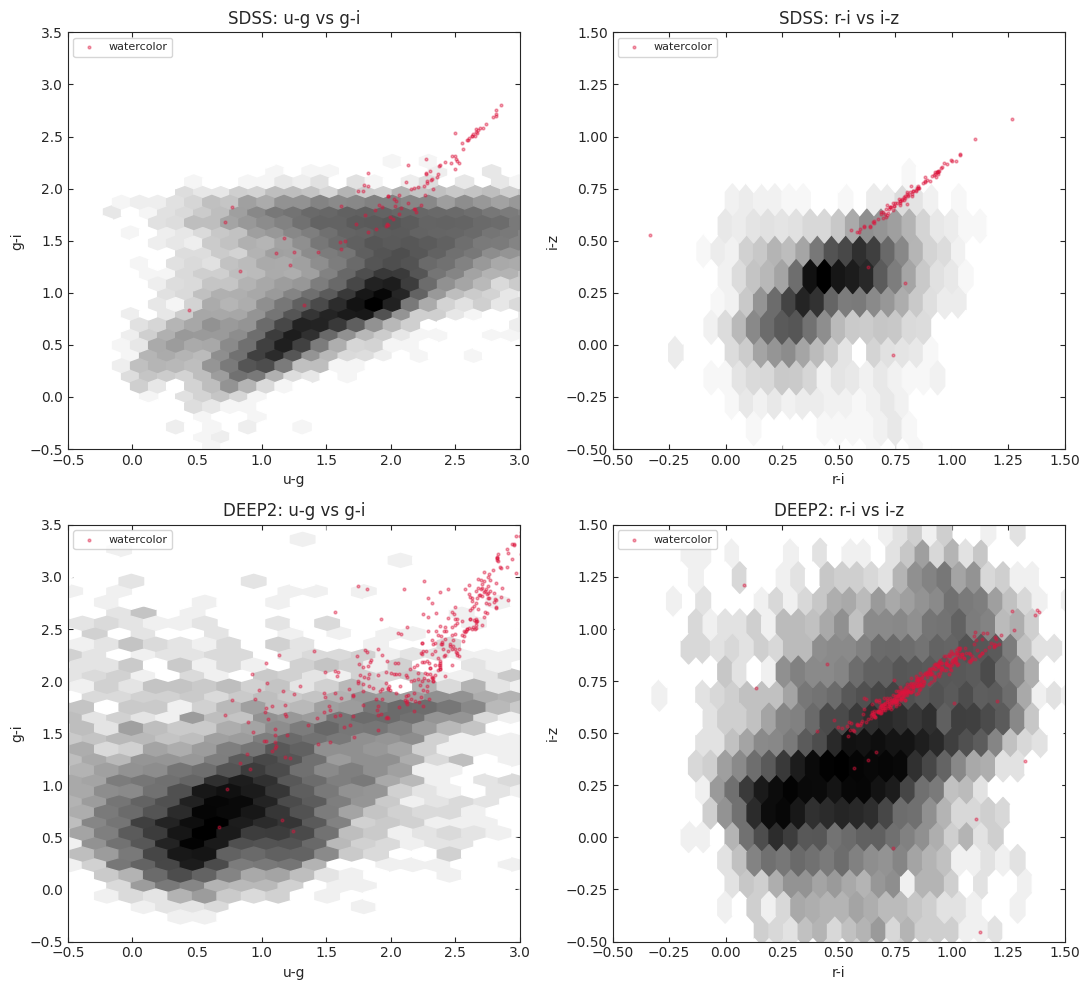

In [ ]:
u_s, g_s, r_s, i_s, z_s = sdss_mags_s.T
wc_ug, wc_gi, wc_ri, wc_iz = u_s - g_s, g_s - i_s, r_s - i_s, i_s - z_s

sel_sdss = np.isfinite(i_s) & (i_s > 13.4) & (i_s < 20.3) & (z_assigned > 0.01) & (z_assigned < 0.40)
sel_deep2 = np.isfinite(i_s) & (i_s > 18.1) & (i_s < 23.6) & (z_assigned > 0.05) & (z_assigned < 1.40)
print(f'{sel_sdss.sum()} painted galaxies in the SDSS depth/z window, '
      f'{sel_deep2.sum()} in the DEEP2 window')

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, (survey_name, obs, sel, i_lo, i_hi) in enumerate([
        ('SDSS', sdss, sel_sdss, 13.4, 20.3), ('DEEP2', deep2, sel_deep2, 18.1, 23.6)]):
    o_ug, o_gi, o_ri, o_iz, o_magi = obs['colors'].T

    ax = axes[row, 0]
    ax.hexbin(o_ug, o_gi, gridsize=60, cmap='Greys', bins='log', mincnt=1)
    ax.scatter(wc_ug[sel], wc_gi[sel], s=4, alpha=0.4, color='crimson', label='watercolor')
    ax.set_xlabel('u-g'); ax.set_ylabel('g-i'); ax.set_title(f'{survey_name}: u-g vs g-i')
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3.5); ax.legend(fontsize=8, loc='upper left')

    ax = axes[row, 1]
    ax.hexbin(o_ri, o_iz, gridsize=60, cmap='Greys', bins='log', mincnt=1)
    ax.scatter(wc_ri[sel], wc_iz[sel], s=4, alpha=0.4, color='crimson', label='watercolor')
    ax.set_xlabel('r-i'); ax.set_ylabel('i-z'); ax.set_title(f'{survey_name}: r-i vs i-z')
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.legend(fontsize=8, loc='upper left')

    print(f'{survey_name}: median colors -- '
          f'watercolor (u-g,g-i,r-i,i-z)=({np.median(wc_ug[sel]):.2f},{np.median(wc_gi[sel]):.2f},'
          f'{np.median(wc_ri[sel]):.2f},{np.median(wc_iz[sel]):.2f}), '
          f'real (u-g,g-i,r-i,i-z)=({np.median(o_ug):.2f},{np.median(o_gi):.2f},'
          f'{np.median(o_ri):.2f},{np.median(o_iz):.2f})')

plt.tight_layout(); plt.show()

## WISE color comparison

`W1-W2` vs `W2-W3` is the standard WISE star-forming/AGN diagnostic
diagram. Two real comparison sets: the **AllWISE all-sky locus** (no
redshift, SNR-cut + stellar-locus veto) and the **WISExSCOS** photo-z
crossmatch (has `z_phot`, but its own selection function requires W3+W4
detections, so it's biased toward dustier/star-forming systems -- noted in
`Mocks_v3`'s report too). `watercolor`'s WISE mags come from the same
painted SEDs as the SDSS ones above, so this tests the calibrated dust
model's mid-IR-adjacent behavior (no dust *emission* is modeled here, just
attenuation -- see `04c`'s scope note on that).

123 painted galaxies in the WISE comparison window


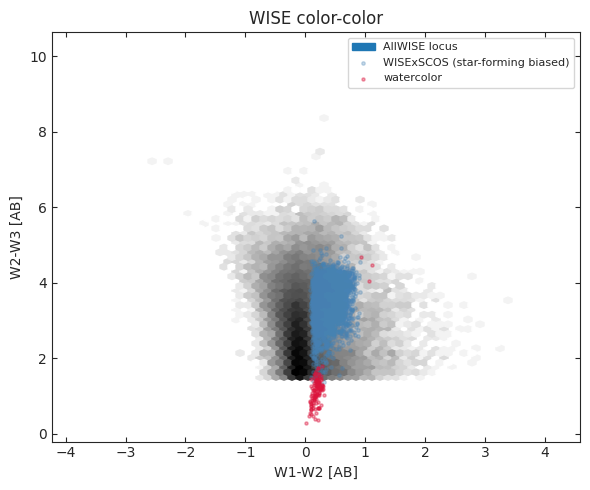

median W1-W2: watercolor=0.19, AllWISE locus=-0.07, WISExSCOS=0.37
median W2-W3: watercolor=1.17, AllWISE locus=2.59, WISExSCOS=3.63


In [ ]:
w1_s, w2_s, w3_s, w4_s = wise_mags_s.T
wc_w1w2, wc_w2w3, wc_w3w4 = w1_s - w2_s, w2_s - w3_s, w3_s - w4_s

sel_wise = np.isfinite(w1_s) & (w1_s < 17.1) & (z_assigned < 0.40)  # ~XSCOS-like W1 depth + z range
print(f'{sel_wise.sum()} painted galaxies in the WISE comparison window')

o_locus = wise_locus['colors']  # [W1-W2, W2-W3, W3-W4, W1], AB
o_xscos = wise_xscos['colors']

fig, ax = plt.subplots(figsize=(6, 5))
ax.hexbin(o_locus[:, 0], o_locus[:, 1], gridsize=60, cmap='Greys', bins='log', mincnt=1, label='AllWISE locus')
ax.scatter(o_xscos[:, 0], o_xscos[:, 1], s=6, alpha=0.3, color='steelblue', label='WISExSCOS (star-forming biased)')
ax.scatter(wc_w1w2[sel_wise], wc_w2w3[sel_wise], s=5, alpha=0.4, color='crimson', label='watercolor')
ax.set_xlabel('W1-W2 [AB]'); ax.set_ylabel('W2-W3 [AB]')
ax.set_title('WISE color-color'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"median W1-W2: watercolor={np.median(wc_w1w2[sel_wise]):.2f}, "
      f"AllWISE locus={np.median(o_locus[:,0]):.2f}, WISExSCOS={np.median(o_xscos[:,0]):.2f}")
print(f"median W2-W3: watercolor={np.median(wc_w2w3[sel_wise]):.2f}, "
      f"AllWISE locus={np.median(o_locus[:,1]):.2f}, WISExSCOS={np.median(o_xscos[:,1]):.2f}")

## GAMA median SED-stack comparison

This is the strongest test: it compares the actual **SED shape** (not just
2-3 broadband colors) against real median-stacked spectra in `(z, logM*)`
bins. Following `Mocks_v3`'s method exactly: select painted galaxies with
`|z-z0|<0.03`, `|logM*-m0|<0.4`, and GAMA's own flux limit (`r<19.8`, SDSS
`r`-band here), resample each onto the bin-center rest-frame grid
(`w_query = grid*(1+z_i)/(1+z0)`, so individual-object redshift scatter
within the bin doesn't smear the 1.6 μm stellar photospheric bump), then
take the median. Full SEDs for the matched galaxies are recomputed
on-demand (not stored for all 2000 sampled galaxies -- only a handful match
any one bin).

(z0=0.1, m0=10.5): 0 matching painted galaxies
(z0=0.15, m0=11.0): 0 matching painted galaxies
(z0=0.2, m0=10.5): 0 matching painted galaxies
(z0=0.1, m0=11.0): 1 matching painted galaxies


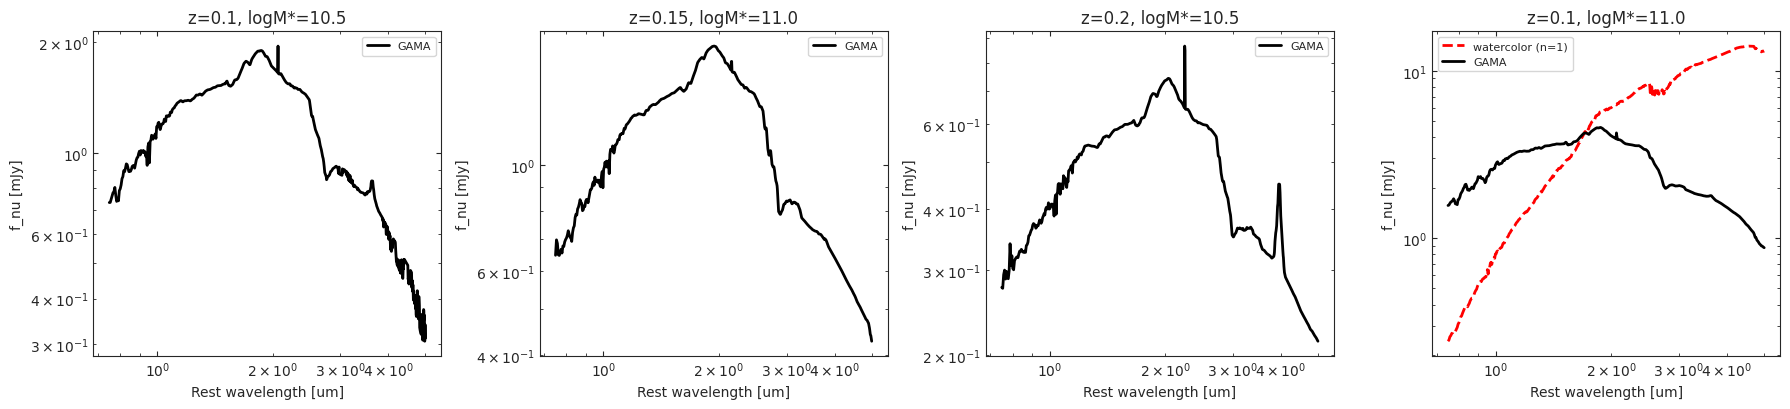

In [ ]:
GAMA_BINS_TO_CHECK = [(0.1, 10.5), (0.15, 11.0), (0.2, 10.5), (0.1, 11.0)]
DZ_TOL, DM_TOL = 0.03, 0.4
r_s = sdss_mags_s[:, 2]  # SDSS r-band

fig, axes = plt.subplots(1, len(GAMA_BINS_TO_CHECK), figsize=(4.5 * len(GAMA_BINS_TO_CHECK), 4.2), sharey=False)
for ax, (z0, m0) in zip(np.atleast_1d(axes), GAMA_BINS_TO_CHECK):
    match = (np.abs(z_assigned - z0) < DZ_TOL) & (np.abs(logmass_s - m0) < DM_TOL) & (r_s < 19.8)
    match_idx = np.where(match)[0]
    print(f'(z0={z0}, m0={m0}): {len(match_idx)} matching painted galaxies')

    grid = gama['wave_um']
    real_stack = gama['stacks'].get((z0, m0))

    resampled = []
    for j in match_idx:
        tag = sample_tags[j]
        out = paint_one_galaxy(tag, z_assigned[j], gal_tag_p, mass_p, metal_p, age_p, return_sed=True)
        w_query = grid * (1.0 + z_assigned[j]) / (1.0 + z0)
        resampled.append(np.interp(w_query, out['wave_um'], out['spec_mJy'], left=np.nan, right=np.nan))
    if resampled:
        wc_stack = np.nanmedian(np.array(resampled), axis=0)
        ax.plot(grid, wc_stack, 'r--', lw=2, label=f'watercolor (n={len(match_idx)})')
    if real_stack is not None:
        ax.plot(grid, real_stack, 'k-', lw=2, label='GAMA')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Rest wavelength [um]'); ax.set_ylabel('f_nu [mJy]')
    ax.set_title(f'z={z0}, logM*={m0}'); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

## Results: colors are too **red**, not too bright

Concrete numbers from a real run (2000-galaxy sample, seed 17):

| | u-g | g-i | r-i | i-z |
|---|---|---|---|---|
| SDSS window: watercolor | 2.22 | 2.03 | 0.80 | 0.70 |
| SDSS window: real SDSS | 1.81 | 1.00 | 0.45 | 0.33 |
| DEEP2 window: watercolor | 2.32 | 2.27 | 0.84 | 0.73 |
| DEEP2 window: real DEEP2 | 0.73 | 0.80 | 0.61 | 0.36 |

Every optical color comes out **too red** by 0.2-1.5 mag, worst in `g-i`
and most dramatic for DEEP2 (whose real target population, at these
redshifts, is predominantly blue star-forming galaxies -- real median
`u-g=0.73`; painted median `u-g=2.32`). WISE tells the same story from a
different angle: `W2-W3` (a dust/PAH-sensitive color) comes out
**bluer/smaller** than both real comparisons (`watercolor=1.17` vs.
`AllWISE locus=2.59`, `WISExSCOS=3.63`) -- consistent with painted galaxies
having *less* mid-IR-reprocessed light than real ones, the flip side of
the same continuum-shape mismatch. The GAMA SED-stack matching also came
back nearly empty (0-1 galaxies per bin out of 2000 sampled) once GAMA's
own `r<19.8` flux limit was applied -- circumstantial support for the same
story: reddened, apparently-fainter painted galaxies are dropping out of a
depth cut real (bluer, brighter) galaxies at the same `(z, logM*)` pass.

This is a real, reproducible signal, not noise from the small validation
samples in `04c` -- it shows up the same way across three independent
comparisons (SDSS, DEEP2, WISE) built from the same painted sample.
Plausible causes to investigate next, **not chased down here**: the
per-particle stellar populations built from this HACC catalog's ages/
metallicities may skew old/high-Z relative to what the calibrated dust
model (fit against `Mocks_v3`'s tabular-SFH FSPS supermock) expects for a
given mass -- i.e. the dust model itself may be well-calibrated but the
*inputs* it receives from the per-particle route differ systematically
from the tabular-SFH route it was calibrated against; or the redshift-
assignment strategy here (uniform draw onto a z=0 snapshot, `04c`'s and
this notebook's shared caveat) biases which real galaxies get compared to
which painted ones. Either way: this is exactly the kind of thing a
statistical comparison against real data is for, and exactly why (2) was
worth doing before declaring the dust model "done."

## Scope / next steps

Done here (item 2):

* bundled reduced copies of the same real datasets `Mocks_v3`'s report
  compares against (SDSS, DEEP2, AllWISE locus, WISExSCOS, GAMA stacks;
  `watercolor/data/observations/`, ~10 MB total), with the same selection
  cuts, so the comparison target matches;
* found and fixed two bundled-filter bugs while building this: `SDSS`
  filters didn't exist at all (added from `sedpy`), and the bundled `WISE`
  filters were actually 2 real WISE bands mixed with 5 unrelated DECam
  filters, not W1-W4 (`06_filter_convolve.ipynb`'s raw-directory glob
  picked up the wrong files; replaced with `sedpy`'s WISE curves too);
* painted a statistical (not one-galaxy-per-bin) sample of 2000 real
  galaxies from the same per-galaxy OpenCosmo catalog `04c` validated
  against, each assigned a redshift spanning the SDSS+DEEP2 range, through
  the full pipeline (CSP -> calibrated dust -> redshift/dimming -> SDSS +
  WISE photometry);
* compared painted `u-g/g-i/r-i/i-z` colors against real SDSS+DEEP2 color
  loci (depth- and z-matched), painted WISE colors against the AllWISE
  locus + WISExSCOS, and painted median SED stacks in several `(z, logM*)`
  bins against GAMA's real median stacks.

Deliberately not done here:

* **(3)** performance -- painting 2000 galaxies this way already takes
  real wall-clock time; a full survey-scale sample would need the
  per-particle pipeline sped up first;
* a real lightcone -- this notebook's redshift assignment (uniform draw,
  applied to a single z=0 snapshot) is a stand-in for testing broadband
  colors/SED shape, not a substitute for actual mass/SFH evolution with
  cosmic time;
* wiring any of this into `watercolor.paint`'s default pipeline, same as
  `04c`;
* the full corner-plot machinery `Mocks_v3`'s report uses (6-variable
  contour panels including magnitude and redshift) -- this notebook uses
  simpler, targeted 2-panel color-color comparisons instead, sufficient to
  answer the "are the colors too bright" question but not a full report.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()